# Wine Recognition - Modelo de clasificación

**Cloud Computing | Kubernetes | Entrega 1**

Entrena un clasificador sobre el dataset katossky/wine-recognition (178 vinos, 13 variables químicas -> `label` 1/2/3)

**TL;DR:** le enseñamos a un programa a adivinar el tipo de un vino (1, 2 o 3) mirando sus medidas químicas. Acierta 35 de 36 vinos que nunca había visto.

In [1]:
# Instala las herramientas que necesita el notebook
%pip install -q pandas==3.1.0 scikit-learn==1.9.1 joblib==1.6.0 matplotlib==3.11.2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Users\andre\mucsi-deusto-code\cloud-computing\mucsi-cloud-computing-wine-recognition\.venv\Scripts\python.exe -m pip install --upgrade pip


In [2]:
# Prepara las herramientas para poder usarlas
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Estilo limpio para todas las gráficas
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
    }
)

In [3]:
# Descarga la tabla de vinos: cada fila es un vino
DATA_URL = (
    "https://huggingface.co/datasets/katossky/wine-recognition/resolve/main/wine.csv"
)
df = pd.read_csv(DATA_URL)

## Estudio del conjunto de datos

**TL;DR:** antes de enseñar nada, miramos cómo son los datos.

In [4]:
print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isna().sum().sum())  # Nulos = datos que faltan
print("Vinos por tipo:", df["label"].value_counts().sort_index().to_dict())
display(df.describe().T)  # Resumen de cada medida: media, mínimo, máximo...
display(df.groupby("label").mean().T)  # Media de cada medida por tipo de vino

Filas y columnas: (178, 14)
Valores nulos: 0
Vinos por tipo: {1: 59, 2: 71, 3: 48}


,count,mean,std,min,25%,50%,75%,max
label,178.0,1.938202,0.775035,1.00,1.0000,2.000,3.0000,3.00
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity of ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58


label,1,2,3
alcohol,13.744746,12.278732,13.153750
malic acid,2.010678,1.932676,3.333750
ash,2.455593,2.244789,2.437083
alcalinity of ash,17.037288,20.238028,21.416667
magnesium,106.338983,94.549296,99.312500
total phenols,2.840169,2.258873,1.678750
flavanoids,2.982373,2.080845,0.781458
nonflavanoid phenols,0.290000,0.363662,0.447500
proanthocyanins,1.899322,1.630282,1.153542
color intensity,5.528305,3.086620,7.396250


**En resumen:**
- No falta ningún dato.
- Hay bastantes vinos de cada tipo (59, 71 y 48).
- Algunas medidas tienen números enormes (`proline` llega a 1680) y otras muy pequeños (`hue` llega a 1.71). Por eso luego las ponemos todas en la misma escala.

**TL;DR de la gráfica de abajo:** ningún tipo se queda casi sin ejemplos, así que el modelo puede aprender los tres.

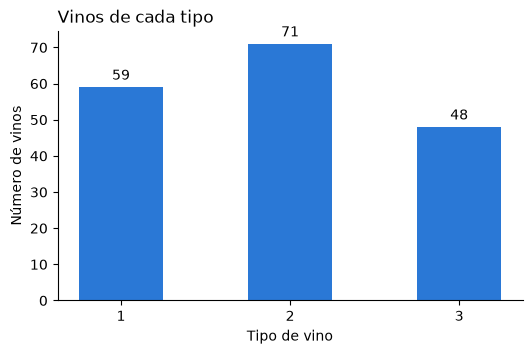

In [5]:
counts = df["label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(counts.index.astype(str), counts.values, width=0.5, color="#2a78d6")
ax.bar_label(bars, padding=3)
ax.set_title("Vinos de cada tipo")
ax.set_xlabel("Tipo de vino")
ax.set_ylabel("Número de vinos")
plt.show()

**TL;DR de la gráfica de abajo:** cada punto es un vino. Con solo 2 medidas, cada tipo tiende a quedarse en su zona: el tipo 1 se separa bien, y los tipos 2 y 3 se mezclan un poco. El modelo usa las 13 medidas, así que tiene más pistas para separarlos.

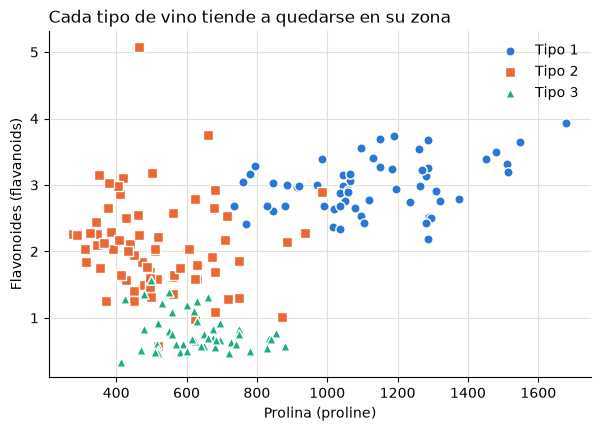

In [6]:
TYPE_STYLES = {1: ("#2a78d6", "o"), 2: ("#eb6834", "s"), 3: ("#1baf7a", "^")}

fig, ax = plt.subplots(figsize=(7, 4.5))
for wine_type, (color, marker) in TYPE_STYLES.items():
    wines = df[df["label"] == wine_type]
    ax.scatter(
        wines["proline"],
        wines["flavanoids"],
        c=color,
        marker=marker,
        s=45,
        edgecolors="white",
        linewidths=1,
        label=f"Tipo {wine_type}",
    )
ax.set_title("Cada tipo de vino tiende a quedarse en su zona")
ax.set_xlabel("Prolina (proline)")
ax.set_ylabel("Flavonoides (flavanoids)")
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.show()

## Pruebas

**TL;DR:** probamos 3 modelos y nos quedamos con el mejor. Es como poner 5 exámenes a 3 alumnos y comparar sus medias (eso es `cv=5`).

In [7]:
# X = las pistas (medidas del vino) | y = la respuesta (tipo de vino)
X = df.drop(columns="label")
y = df["label"]

# Separa los vinos: 80% para estudiar (train) y 20% para el examen final (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Los 3 modelos que compiten
candidates = {
    "Regresión logística": make_pipeline(
        StandardScaler(), 
        LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    "Random Forest": RandomForestClassifier(random_state=42),
}

# Cada modelo hace 5 exámenes. Media = cuánto acierta | Desviación = cuánto cambia su nota
cv_means = {}
for name, candidate in candidates.items():
    scores = cross_val_score(candidate, X_train, y_train, cv=5)
    cv_means[name] = scores.mean()
    print(f"{name}: {scores.mean():.3f} | Desviación {scores.std():.3f}")

Regresión logística: 0.993 | Desviación 0.014
KNN: 0.965 | Desviación 0.038


Random Forest: 0.986 | Desviación 0.028


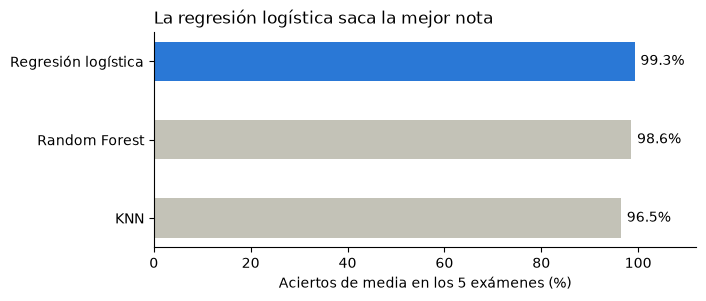

In [8]:
ranking = pd.Series(cv_means).sort_values()
colors = ["#2a78d6" if name == ranking.idxmax() else "#c3c2b7" for name in ranking.index]

fig, ax = plt.subplots(figsize=(7, 2.8))
bars = ax.barh(ranking.index, ranking.values * 100, height=0.5, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set_title("La regresión logística saca la mejor nota")
ax.set_xlabel("Aciertos de media en los 5 exámenes (%)")
ax.set_xlim(0, 112)
plt.show()

## Modelo final y evaluación

**TL;DR:** elegimos la regresión logística porque tiene la mejor nota (0.993) y la más estable. Ahora la entrenamos y le ponemos el examen final, con vinos que no se han usado en las pruebas.

In [9]:
# Crea el modelo: primero iguala las escalas y luego decide el tipo de vino
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# Entrena el modelo: aprende a reconocer cada tipo de vino a partir de los ejemplos
model.fit(X_train, y_train)
# Examen final: porcentaje de aciertos en vinos que no ha visto (0.972 = 97,2%)
print("Accuracy test:", round(model.score(X_test, y_test), 3))

# Pide al modelo sus respuestas y las compara con las reales
y_pred = model.predict(X_test)
print("Matriz de confusión (filas: real, columnas: predicción):")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy test: 0.972
Matriz de confusión (filas: real, columnas: predicción):
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



**TL;DR de la gráfica de abajo:** la diagonal son aciertos (12 + 14 + 9 = 35). Cualquier número fuera de la diagonal es un fallo: aquí hay 1 vino de tipo 3 que el modelo confundió con tipo 2.

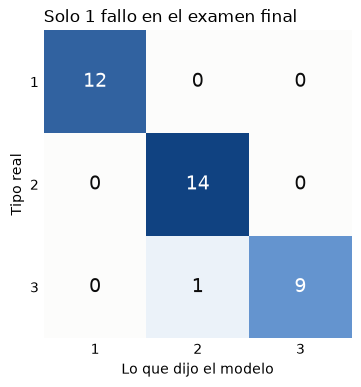

In [10]:
matrix = confusion_matrix(y_test, y_pred)
wine_types = [1, 2, 3]
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#86b6ef", "#104281"])

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap=blues)
for row in range(3):
    for col in range(3):
        value = matrix[row, col]
        text_color = "white" if value > matrix.max() / 2 else "#0b0b0b"
        ax.text(col, row, value, ha="center", va="center", color=text_color, fontsize=14)
ax.set_xticks(range(3), wine_types)
ax.set_yticks(range(3), wine_types)
ax.set_title("Solo 1 fallo en el examen final")
ax.set_xlabel("Lo que dijo el modelo")
ax.set_ylabel("Tipo real")
ax.spines[["left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
plt.show()

In [11]:
# Guarda el modelo en un archivo para no tener que entrenarlo otra vez
Path("model").mkdir(exist_ok=True)
joblib.dump(model, "model/wine-model.joblib")

# Comprobación: cargar el archivo y predecir
loaded = joblib.load("model/wine-model.joblib")
print("Predicción:", loaded.predict(X_test.head(3)), "| Real:", y_test.head(3).tolist())

Predicción: [1 2 1] | Real: [1, 3, 1]


## Resultados

**TL;DR:** el modelo acierta 35 de 36 vinos (97,2%).

- Su único fallo es el vino de tipo 3 que confundió con tipo 2, el mismo que se ve en la comprobación de arriba.
- La nota es parecida a la de las pruebas (99,3%), así que no parece casualidad.
- Ojo: el examen tiene solo 36 vinos, así que cada fallo baja la nota casi 3 puntos.